# Лабораторная работа №2: диалоговые модели (decoder-only и encoder-decoder)

**Задача:** по истории диалога предсказать следующий ответ **системы** на запрос **пользователя**.
Две модели с разной архитектурой дообучаются на одном и том же датасете, качество до и после дообучения измеряется метриками **BLEU** и **METEOR** на валидационном сабсете.

| | Decoder-only | Encoder-decoder |
|---|---|---|
| Модель | `HuggingFaceTB/SmolLM2-360M-Instruct` | `google/flan-t5-base` |
| Вход / выход | один поток: промпт → продолжение | энкодер читает промпт, декодер генерирует ответ |

Для каждой модели выполняются шаги 3–8 из задания:

3. zero-shot проверка в сценарии, близком к датасету → 4. BLEU/METEOR исходной модели → 5. дообучение → 6. проверка обученной модели → 7. BLEU/METEOR обученной модели → 8. сравнение.

Чтобы сравнение «до/после» было честным, **промпт, параметры генерации и валидационный сабсет одинаковы** на обеих стадиях; меняются только веса модели.

In [1]:
import os, json, random, time, gc, functools
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from IPython.display import display

import datasets as hf_datasets
import transformers
import nltk
import sacrebleu
from datasets import load_dataset
from nltk.translate.meteor_score import meteor_score
from transformers import (AutoTokenizer, AutoModelForCausalLM, AutoModelForSeq2SeqLM,
                          get_linear_schedule_with_warmup)

for pkg in ["wordnet", "omw-1.4", "punkt_tab"]:      # данные для METEOR и токенизации
    nltk.download(pkg, quiet=True)
hf_datasets.disable_progress_bars()
transformers.utils.logging.set_verbosity_error()
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

[nltk_data] Error loading wordnet: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.
[nltk_data] Error loading omw-1.4: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be S

device: cuda | NVIDIA GeForce RTX 3070 Ti


## Конфигурация

Одинаковые условия для обеих моделей: эффективный батч 16, 2 эпохи, линейный планировщик с прогревом,
bf16-autocast. Скорость обучения подобрана «по умолчанию» для каждой архитектуры (подбор не проводился).

In [ ]:
DATASET = "pfb30/multi_woz_v22"
PARQUET_REVISION = "refs/convert/parquet"   # datasets>=4 не запускает скрипты загрузки, берём parquet-конвертацию
SEED = 0

MAX_HISTORY_TURNS = 6 # сколько предыдущих реплик показываем модели
MAX_PROMPT_TOKENS = 320 # если промпт длиннее - отбрасываем самые старые реплики
MAX_NEW_TOKENS = 64
N_TRAIN = 12000 # размер обучающй подвыборки (из 56 776 примеров train)
N_VAL = 1000 # размер валидационной подвыборки для BLEU/METEOR (из 7 374 примеров validation)
N_VAL_LOSS = 500 # на скольких из них считать val-loss для кривых обучения
EPOCHS = 2
BATCH_SIZE = 16 # эффективный (micro-batch х накопление градиента)
GEN_BATCH_SIZE = 32
N_BOOTSTRAP = 1000

MODELS = {
    "decoder": {"name": "HuggingFaceTB/SmolLM2-360M-Instruct", "title": "Decoder-only (SmolLM2-360M-Instruct)",
                "short": "Decoder-only", "lr": 3e-5, "micro_bs": 8},
    "encdec": {"name": "google/flan-t5-base", "title": "Encoder-decoder (Flan-T5-base)",
               "short": "Encoder-decoder", "lr": 1e-4, "micro_bs": 16},
}
STAGE_TITLE = {"base": "исходная модель (zero-shot)", "tuned": "дообученная модель"}

RESULTS_DIR = "results_lab2"
CKPT_DIR = "checkpoints_lab2"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(CKPT_DIR, exist_ok=True)


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def free_gpu():
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()


def cached(path, fn):
    """Результат дорогой стадии (обучение, генерация) сохраняется в json: повторный запуск ноутбука её пропускает."""
    if os.path.exists(path):
        return json.load(open(path, encoding="utf-8"))
    out = fn()
    json.dump(out, open(path, "w", encoding="utf-8"), ensure_ascii=False, indent=1)
    return out

## 1. Выбор моделей

Нужны две диалоговые модели разной архитектуры, которые можно **дообучить целиком** на видеокарте с 8 ГБ.

* **Decoder-only - [`SmolLM2-360M-Instruct`](https://huggingface.co/HuggingFaceTB/SmolLM2-360M-Instruct)** (Llama-подобная, 362M параметров). Instruction-tuned: в zero-shot ей можно задать роль «система» через chat-шаблон.
* **Encoder-decoder - [`flan-t5-base`](https://huggingface.co/google/flan-t5-base)** (T5, 248M параметров). Тоже instruction-tuned (Flan), поэтому zero-shot базовая линия осмысленна: модель умеет выполнять инструкцию из промпта.

Обе модели инструктивные, поэтому в zero-shot получают один и тот же смысловой промпт (роль + история диалога). Более крупные варианты (например, SmolLM2-1.7B или flan-t5-large) на 8 ГБ полностью не дообучаются, а LoRA я не использую, чтобы файнтюнинг был полным.

**Оговорка:** модели различаются не только архитектурой, но и размером, данными предобучения и токенизатором, поэтому прямое сопоставление decoder-only и encoder-decoder в конце - ориентировочное. Строго сравнивается каждая модель сама с собой до и после дообучения (шаг 8).

## 2. Выбор датасета

**[MultiWOZ 2.2](https://huggingface.co/datasets/pfb30/multi_woz_v22)** - размеченные людьми целевые диалоги пользователь ↔ система (информационный центр Кембриджа: рестораны, отели, достопримечательности, поезда, такси, больница, полиция). В каждой реплике указан говорящий, поэтому задача формулируется напрямую:
**история диалога, оканчивающаяся репликой пользователя → следующая реплика системы.**

Как строятся примеры:
* для каждой реплики системы берём до `MAX_HISTORY_TURNS` предыдущих реплик;
* из 56 776 обучающих примеров случайно берём `N_TRAIN` (обучающий сабсет), из 7 374 валидационных - `N_VAL`
  (валидационный сабсет, на нём считаются все метрики);
* разбиение train/validation сделано авторами **по диалогам**, поэтому утечки между ними нет.

**Ограничение датасета:** настоящие ответы системы опираются на базу данных (названия отелей, номера телефонов, коды бронирования), которой у модели нет. Поэтому абсолютные BLEU/METEOR здесь невысокие даже у хорошей модели - смысл эксперимента в относительном приросте после дообучения.

In [ ]:
raw = load_dataset(DATASET, revision=PARQUET_REVISION,
                   data_files={s: f"v2.2/{s}/0000.parquet" for s in ["train", "validation"]})
print({k: f"{len(v)} диалогов" for k, v in raw.items()})   # в parquet-ветке лежат две конфигурации; берём чистую v2.2


def build_examples(split):
    out = []
    for d in raw[split]:
        speakers, utts = d["turns"]["speaker"], d["turns"]["utterance"]
        for i in range(1, len(utts)):
            if speakers[i] == 1 and speakers[i - 1] == 0:           # ответ системы на реплику пользователя
                lo = max(0, i - MAX_HISTORY_TURNS)
                history = [{"role": "user" if s == 0 else "system", "text": u.strip()}
                           for s, u in zip(speakers[lo:i], utts[lo:i])]
                out.append({"dialogue_id": d["dialogue_id"], "history": history, "response": utts[i].strip()})
    return out


all_train, all_val = build_examples("train"), build_examples("validation")
rng = random.Random(SEED)
train_examples = rng.sample(all_train, N_TRAIN)
val_examples = rng.sample(all_val, N_VAL)
REFS = [ex["response"] for ex in val_examples]
REF_WORDS = float(np.mean([len(r.split()) for r in REFS]))

stats = pd.DataFrame({
    "примеров всего": [len(all_train), len(all_val)],
    "в сабсете": [len(train_examples), len(val_examples)],
    "диалогов в сабсете": [len({e["dialogue_id"] for e in train_examples}), len({e["dialogue_id"] for e in val_examples})],
    "слов в ответе системы (среднее)": [np.mean([len(e["response"].split()) for e in s]).round(1) for s in (train_examples, val_examples)],
}, index=["train", "validation"])
display(stats)

ex = val_examples[0]
print("Пример из валидационного сабсета:")
for t in ex["history"]:
    print(f"  {t['role']:>6}: {t['text']}")
print(f"  ОТВЕТ СИСТЕМЫ (эталон): {ex['response']}")

{'train': '8437 диалогов', 'validation': '1000 диалогов'}


,примеров всего,в сабсете,диалогов в сабсете,слов в ответе системы (среднее)
train,56776,12000,6384,14.9
validation,7374,1000,637,15.0


Пример из валидационного сабсета:
  system: Why yes, it's a great attraction. It is located at the centre on downing street. The entrance fee for the museum is free.
    user: What is the phone number?
  system: 01223333516 is the phone number, is there anything else I can assist you with today?
    user: Yes. I would like to book a train from Leicester.
  system: OK, what is your travel day, and what time do you need to travel?
    user: I'm leaving from Leicester on Wednesday and going to Cambridge. Want to leave after 11
  ОТВЕТ СИСТЕМЫ (эталон): TR9776 leaves at 11:09. Does that work for you?


## Общий код: промпты, генерация, метрики, обучение

**Промпты.** Содержание одно и то же, формат - родной для каждой архитектуры:
* decoder-only: chat-шаблон модели (`system` - инструкция, затем реплики пользователя/ассистента по ролям);
* encoder-decoder: текст `инструкция + Dialogue: … + Assistant:`, который читает энкодер.

Инструкция намеренно простая и без мета-терминов: в первом варианте со словами «system side of a dialogue» модель буквально понимала «system» и отказывалась помогать, что искусственно занижало бы zero-shot-базу. Результат zero-shot, разумеется, зависит от формулировки промпта - подбор промпта в работе не проводился.

In [4]:
INSTRUCTION = ("You are a helpful assistant at the Cambridge city information centre. "
               "You help visitors with restaurants, hotels, attractions, trains, taxis, hospitals and police. "
               "Reply to the user's last message in one or two short sentences.")


def decoder_prompt(history, tok):
    messages = [{"role": "system", "content": INSTRUCTION}]
    messages += [{"role": "user" if t["role"] == "user" else "assistant", "content": t["text"]} for t in history]
    return tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)


def encdec_prompt(history, tok):
    lines = [f"{'User' if t['role'] == 'user' else 'Assistant'}: {t['text']}" for t in history]
    return f"{INSTRUCTION}\n\nDialogue:\n" + "\n".join(lines) + "\nAssistant:"


PROMPT_FN = {"decoder": decoder_prompt, "encdec": encdec_prompt}


@functools.lru_cache(maxsize=None)
def get_tokenizer(kind):
    tok = AutoTokenizer.from_pretrained(MODELS[kind]["name"])
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    return tok


def build_prompt(kind, history):
    """Промпт для истории; если он длиннее MAX_PROMPT_TOKENS, отбрасываем самые старые реплики."""
    tok, h = get_tokenizer(kind), list(history)
    while True:
        prompt = PROMPT_FN[kind](h, tok)
        if len(h) <= 1 or len(tok(prompt, add_special_tokens=False).input_ids) <= MAX_PROMPT_TOKENS:
            return prompt
        h = h[1:]


print("Пример промпта для decoder-only:\n" + "-" * 60)
print(build_prompt("decoder", val_examples[0]["history"][-2:]))
print("-" * 60 + "\nПример промпта для encoder-decoder:\n" + "-" * 60)
print(build_prompt("encdec", val_examples[0]["history"][-2:]))

Пример промпта для decoder-only:
------------------------------------------------------------
<|im_start|>system
You are a helpful assistant at the Cambridge city information centre. You help visitors with restaurants, hotels, attractions, trains, taxis, hospitals and police. Reply to the user's last message in one or two short sentences.<|im_end|>
<|im_start|>assistant
OK, what is your travel day, and what time do you need to travel?<|im_end|>
<|im_start|>user
I'm leaving from Leicester on Wednesday and going to Cambridge. Want to leave after 11<|im_end|>
<|im_start|>assistant

------------------------------------------------------------
Пример промпта для encoder-decoder:
------------------------------------------------------------
You are a helpful assistant at the Cambridge city information centre. You help visitors with restaurants, hotels, attractions, trains, taxis, hospitals and police. Reply to the user's last message in one or two short sentences.

Dialogue:
Assistant: OK, wh

**Генерация.** Жадное декодирование (`do_sample=False`), не более `MAX_NEW_TOKENS` новых токенов - одинаково для
обеих моделей и обеих стадий. Модели для инференса грузятся в bf16.

In [ ]:
def load_model(kind, stage, dtype=torch.bfloat16):
    path = MODELS[kind]["name"] if stage == "base" else os.path.join(CKPT_DIR, kind)
    cls = AutoModelForCausalLM if kind == "decoder" else AutoModelForSeq2SeqLM
    return cls.from_pretrained(path, dtype=dtype).to(device).eval()


@torch.no_grad()
def generate_replies(kind, stage, histories):
    """Ответы модели на список историй диалога (стадия: 'base' или 'tuned')."""
    tok = get_tokenizer(kind)
    model = load_model(kind, stage)
    prompts = [build_prompt(kind, h) for h in histories]
    order = np.argsort([-len(p) for p in prompts])               # длинные первыми - меньше паддинга и пик памяти сразу
    replies = [None] * len(prompts)
    gen_kwargs = dict(do_sample=False, max_new_tokens=MAX_NEW_TOKENS, temperature=None, top_p=None, top_k=None)
    if kind == "decoder":
        tok.padding_side = "left"
        gen_kwargs.update(eos_token_id=tok.convert_tokens_to_ids("<|im_end|>"), pad_token_id=tok.pad_token_id)
    for i in range(0, len(prompts), GEN_BATCH_SIZE):
        idx = order[i:i + GEN_BATCH_SIZE]
        batch = [prompts[j] for j in idx]
        if kind == "decoder":
            enc = tok(batch, return_tensors="pt", padding=True, add_special_tokens=False).to(device)
        else:
            enc = tok(batch, return_tensors="pt", padding=True, truncation=True, max_length=MAX_PROMPT_TOKENS + 16).to(device)
        out = model.generate(**enc, **gen_kwargs)
        if kind == "decoder":
            out = out[:, enc["input_ids"].shape[1]:]
        for j, text in zip(idx, tok.batch_decode(out, skip_special_tokens=True)):
            replies[j] = " ".join(text.split())                   # убираем переводы строк и лишние пробелы
    del model
    free_gpu()
    return replies

**Метрики.**
* **BLEU** - `sacreBLEU` (корпусный, токенизация 13a, шкала 0–100);
* **METEOR** - `nltk.translate.meteor_score` (учитывает стемминг и синонимы WordNet), усреднение по предложениям,
  приводится в шкале ×100.

Чтобы отличить реальные улучшения от шума выборки, для каждой метрики считается **bootstrap-интервал** (1000 пересэмплирований 1000 примеров валидации) и **парная разность дообученная − исходная** на тех же пересэмплированных примерах.

In [ ]:
# force=True: в эталонах MultiWOZ перед точкой стоит пробел («… FA6IDT91 .»), sacreBLEU принимает такой текст за уже
# токенизированный и выводит предупреждение. Это только подавление сообщения, значения метрики не меняются.
_bleu = sacrebleu.BLEU(force=True)


def bleu_stats(hyps, refs):
    """Поэлементные статистики BLEU: корпусный BLEU по пересэмплу считается суммированием строк."""
    return np.array(_bleu._extract_corpus_statistics(hyps, [refs]))


def bleu_from_stats(s):
    return _bleu._compute_score_from_stats(s.sum(0).tolist()).score


def sentence_meteor(ref, hyp):
    r, h = nltk.word_tokenize(ref), nltk.word_tokenize(hyp)
    return float(meteor_score([r], h)) if r and h else 0.0


_chk = bleu_stats(["the cat is on the mat", "there is a dog"], ["the cat sat on the mat", "there is a big dog"])
assert abs(bleu_from_stats(_chk) - sacrebleu.corpus_bleu(["the cat is on the mat", "there is a dog"],
                                                          [["the cat sat on the mat", "there is a big dog"]]).score) < 1e-6


def get_eval(kind, stage):
    """Ответы модели на валидационном сабсете + метрики (кэшируется)."""
    def run():
        t0 = time.time()
        hyps = generate_replies(kind, stage, [e["history"] for e in val_examples])
        meteor = [sentence_meteor(r, h) for r, h in zip(REFS, hyps)]
        return {"hyps": hyps, "meteor": meteor, "bleu": sacrebleu.corpus_bleu(hyps, [REFS], force=True).score,
                "meteor_mean": float(np.mean(meteor)), "hyp_words": float(np.mean([len(h.split()) for h in hyps])),
                "seconds": time.time() - t0}
    return cached(os.path.join(RESULTS_DIR, f"eval_{kind}_{stage}.json"), run)


def print_metrics(kind, stage, n_examples=5):
    r = get_eval(kind, stage)
    print(f"{MODELS[kind]['title']} - {STAGE_TITLE[stage]}, валидационный сабсет ({N_VAL} примеров)")
    print(f"  BLEU   = {r['bleu']:.2f}      (sacreBLEU, шкала 0–100)")
    print(f"  METEOR = {100 * r['meteor_mean']:.2f}      (NLTK, среднее по предложениям, ×100)")
    print(f"  средняя длина ответа: модель {r['hyp_words']:.1f} слов, эталон {REF_WORDS:.1f} слов")
    print("\n  Примеры (последняя реплика пользователя → эталон / ответ модели):")
    for ex, hyp in list(zip(val_examples, r["hyps"]))[:n_examples]:
        print(f"   user : {ex['history'][-1]['text']}")
        print(f"   эталон: {ex['response']}")
        print(f"   модель: {hyp}\n")


def bootstrap_report(kind, B=N_BOOTSTRAP, seed=0):
    base, tuned = get_eval(kind, "base"), get_eval(kind, "tuned")
    sb, st = bleu_stats(base["hyps"], REFS), bleu_stats(tuned["hyps"], REFS)
    mb, mt = np.array(base["meteor"]), np.array(tuned["meteor"])
    n, rg = len(REFS), np.random.default_rng(seed)
    draws = {k: [] for k in ["bleu_base", "bleu_tuned", "meteor_base", "meteor_tuned"]}
    for _ in range(B):
        idx = rg.integers(0, n, n)
        draws["bleu_base"].append(bleu_from_stats(sb[idx])); draws["bleu_tuned"].append(bleu_from_stats(st[idx]))
        draws["meteor_base"].append(100 * mb[idx].mean()); draws["meteor_tuned"].append(100 * mt[idx].mean())
    d = {k: np.array(v) for k, v in draws.items()}
    d["bleu_diff"], d["meteor_diff"] = d["bleu_tuned"] - d["bleu_base"], d["meteor_tuned"] - d["meteor_base"]
    ci = lambda a: (float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5)))
    return {k: ci(v) for k, v in d.items()}

**Обучение.** Полное дообучение всех весов, AdamW, bf16-autocast, `gradient checkpointing` (иначе модели не помещаются
в 8 ГБ). Для decoder-only лосс считается **только по токенам ответа** (промпт замаскирован), а логиты словаря
вычисляются только на этих позициях - это сильно экономит память. Для encoder-decoder лосс - стандартный seq2seq
(по токенам ответа).

In [ ]:
def encode_example(kind, ex):
    tok, prompt = get_tokenizer(kind), build_prompt(kind, ex["history"])
    if kind == "decoder":
        p = tok(prompt, add_special_tokens=False).input_ids
        t = tok(ex["response"] + "<|im_end|>", add_special_tokens=False).input_ids[:MAX_NEW_TOKENS + 1]
        return {"input_ids": p + t, "labels": [-100] * len(p) + t}
    x = tok(prompt, truncation=True, max_length=MAX_PROMPT_TOKENS + 16).input_ids
    y = tok(text_target=ex["response"], truncation=True, max_length=MAX_NEW_TOKENS).input_ids
    return {"input_ids": x, "labels": y}


def make_collate(kind):
    pad_id = get_tokenizer(kind).pad_token_id

    def collate(batch):
        n, lx = len(batch), max(len(b["input_ids"]) for b in batch)
        ids, att = torch.full((n, lx), pad_id), torch.zeros((n, lx), dtype=torch.long)
        ly = lx if kind == "decoder" else max(len(b["labels"]) for b in batch)
        lab = torch.full((n, ly), -100)
        for i, b in enumerate(batch):
            ids[i, :len(b["input_ids"])] = torch.tensor(b["input_ids"])
            att[i, :len(b["input_ids"])] = 1
            lab[i, :len(b["labels"])] = torch.tensor(b["labels"])
        return {"input_ids": ids, "attention_mask": att, "labels": lab}
    return collate


def decoder_loss(model, batch):
    hidden = model.model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).last_hidden_state
    labels = batch["labels"][:, 1:]
    keep = labels != -100                                    # логиты словаря - только для токенов ответа
    return F.cross_entropy(model.lm_head(hidden[:, :-1][keep]).float(), labels[keep])


def encdec_loss(model, batch):
    return model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"], labels=batch["labels"]).loss


LOSS_FN = {"decoder": decoder_loss, "encdec": encdec_loss}


@torch.no_grad()
def val_loss(kind, model, data):
    model.eval()
    losses = []
    for batch in DataLoader(data, batch_size=MODELS[kind]["micro_bs"], collate_fn=make_collate(kind)):
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device.type, dtype=torch.bfloat16):
            losses.append(LOSS_FN[kind](model, batch).item())
    model.train()
    return float(np.mean(losses))


def train_model(kind):
    cfg = MODELS[kind]
    set_seed(SEED)
    train_data = [encode_example(kind, e) for e in train_examples]
    val_data = [encode_example(kind, e) for e in val_examples[:N_VAL_LOSS]]
    cls = AutoModelForCausalLM if kind == "decoder" else AutoModelForSeq2SeqLM
    model = cls.from_pretrained(cfg["name"], dtype=torch.float32).to(device)
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.config.use_cache = False
    n_params = sum(p.numel() for p in model.parameters())

    accum = BATCH_SIZE // cfg["micro_bs"]
    dl = DataLoader(train_data, batch_size=cfg["micro_bs"], shuffle=True, collate_fn=make_collate(kind),
                    generator=torch.Generator().manual_seed(SEED))
    steps_per_epoch = len(dl) // accum
    total_steps = EPOCHS * steps_per_epoch
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=0.01, fused=device.type == "cuda")
    sched = get_linear_schedule_with_warmup(opt, int(0.03 * total_steps), total_steps)
    loss_fn = LOSS_FN[kind]
    torch.cuda.reset_peak_memory_stats()

    log = {"kind": kind, "model": cfg["name"], "n_params": n_params, "n_train": len(train_data), "epochs": EPOCHS,
           "lr": cfg["lr"], "batch_size": BATCH_SIZE, "micro_bs": cfg["micro_bs"], "total_steps": total_steps,
           "loss_log": [], "val_loss": [[0, val_loss(kind, model, val_data)]]}
    print(f"[{kind}] {n_params / 1e6:.0f}M params | {total_steps} optimizer steps | val loss до обучения: {log['val_loss'][0][1]:.4f}")

    model.train()
    t0, step, running = time.time(), 0, []
    for epoch in range(1, EPOCHS + 1):
        for i, batch in enumerate(dl):
            if i >= steps_per_epoch * accum:
                break
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.autocast(device.type, dtype=torch.bfloat16):
                loss = loss_fn(model, batch) / accum
            loss.backward()
            running.append(loss.item() * accum)
            if (i + 1) % accum == 0:
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step(); sched.step(); opt.zero_grad(set_to_none=True)
                step += 1
                if step % 25 == 0 or step == total_steps:
                    log["loss_log"].append([step, float(np.mean(running))])
                    print(f"  [{kind}] epoch {epoch} step {step}/{total_steps} | train loss {np.mean(running):.4f} | "
                          f"{(time.time() - t0) / 60:.1f} мин", flush=True)
                    running = []
        log["val_loss"].append([step, val_loss(kind, model, val_data)])
        print(f"  [{kind}] === конец эпохи {epoch}: val loss {log['val_loss'][-1][1]:.4f}", flush=True)

    log["seconds"] = time.time() - t0
    log["peak_mem_gib"] = torch.cuda.max_memory_allocated() / 2 ** 30
    model.config.use_cache = True
    model.save_pretrained(os.path.join(CKPT_DIR, kind))
    get_tokenizer(kind).save_pretrained(os.path.join(CKPT_DIR, kind))
    del model, opt
    free_gpu()
    return log


def get_training(kind):
    return cached(os.path.join(RESULTS_DIR, f"train_{kind}.json"), lambda: train_model(kind))


def print_training(kind):
    log = get_training(kind)
    print(f"{MODELS[kind]['title']}: {log['n_params'] / 1e6:.0f}M параметров, {log['n_train']} примеров × {log['epochs']} эпох, "
          f"эффективный батч {log['batch_size']}, lr {log['lr']}, {log['total_steps']} шагов, "
          f"{log['seconds'] / 60:.1f} мин, пик памяти {log['peak_mem_gib']:.1f} ГиБ")
    print("val loss (teacher forcing, первые %d примеров валидации): " % N_VAL_LOSS +
          " → ".join(f"{v:.3f}" for _, v in log["val_loss"]) + "   (до обучения → после каждой эпохи)")

**Проверка в сценарии, близком к датасету** (шаги 3 и 6). Пять реплик, написанных вручную в духе MultiWOZ
(ресторан, отель, поезд, такси, достопримечательности), плюс три примера из валидации с эталонным ответом.
Одни и те же сценарии показываются до и после дообучения.

In [ ]:
SCENARIOS = [
    [{"role": "user", "text": "Hi, I'm looking for a cheap Italian restaurant in the city centre."}],
    [{"role": "user", "text": "I need a hotel with free parking and wifi for 3 nights starting on Friday."}],
    [{"role": "user", "text": "I need a train to London Kings Cross on Sunday."},
     {"role": "system", "text": "Sure! Where will you be leaving from, and what time would you like to depart?"},
     {"role": "user", "text": "Leaving from Cambridge after 14:00. How long does the trip take?"}],
    [{"role": "user", "text": "Can you book me a taxi from Cambridge train station to the Gonville Hotel? I need to arrive by 9:30."}],
    [{"role": "user", "text": "Are there any free museums to visit in the centre of town?"},
     {"role": "system", "text": "Yes, there are several. Do you have a preference for the type of museum?"},
     {"role": "user", "text": "Something about science, and I'd also like the postcode."}],
]
CHECK_VAL = val_examples[:3]


def get_scenarios(kind, stage):
    def run():
        replies = generate_replies(kind, stage, SCENARIOS + [e["history"] for e in CHECK_VAL])
        return {"replies": replies}
    return cached(os.path.join(RESULTS_DIR, f"scenarios_{kind}_{stage}.json"), run)["replies"]


def print_scenarios(kind, stage):
    replies = get_scenarios(kind, stage)
    print(f"{MODELS[kind]['title']} - {STAGE_TITLE[stage]}\n")
    for i, (hist, reply) in enumerate(zip(SCENARIOS, replies[:len(SCENARIOS)]), 1):
        print(f"--- Сценарий {i} (написан вручную) ---")
        for t in hist:
            print(f"  {t['role']:>6}: {t['text']}")
        print(f"  >>> ОТВЕТ МОДЕЛИ: {reply}\n")
    for i, (ex, reply) in enumerate(zip(CHECK_VAL, replies[len(SCENARIOS):]), 1):
        print(f"--- Пример {i} из валидации ---")
        for t in ex["history"][-3:]:
            print(f"  {t['role']:>6}: {t['text']}")
        print(f"  эталон системы:    {ex['response']}")
        print(f"  >>> ОТВЕТ МОДЕЛИ: {reply}\n")

# Часть A. Decoder-only: SmolLM2-360M-Instruct

## 3. Zero-shot проверка (исходная модель)

In [9]:
print_scenarios("decoder", "base")

Decoder-only (SmolLM2-360M-Instruct) — исходная модель (zero-shot)

--- Сценарий 1 (написан вручную) ---
    user: Hi, I'm looking for a cheap Italian restaurant in the city centre.
  >>> ОТВЕТ МОДЕЛИ: I'm sorry, but as an AI, I don't have the ability to browse the internet or provide real-time information. I can help you with your search for a cheap Italian restaurant in the city centre.

--- Сценарий 2 (написан вручную) ---
    user: I need a hotel with free parking and wifi for 3 nights starting on Friday.
  >>> ОТВЕТ МОДЕЛИ: I'm sorry for the confusion, but as a chatbot, I don't have the ability to provide real-time information or make decisions. I can help you with your queries, but I'm unable to assist with booking or arranging specific services.

--- Сценарий 3 (написан вручную) ---
    user: I need a train to London Kings Cross on Sunday.
  system: Sure! Where will you be leaving from, and what time would you like to depart?
    user: Leaving from Cambridge after 14:00. How lon

## 4. BLEU и METEOR исходной модели

In [10]:
print_metrics("decoder", "base")

Decoder-only (SmolLM2-360M-Instruct) — исходная модель (zero-shot), валидационный сабсет (1000 примеров)
  BLEU   = 2.70      (sacreBLEU, шкала 0–100)
  METEOR = 18.96      (NLTK, среднее по предложениям, ×100)
  средняя длина ответа: модель 21.3 слов, эталон 15.0 слов

  Примеры (последняя реплика пользователя → эталон / ответ модели):
   user : I'm leaving from Leicester on Wednesday and going to Cambridge. Want to leave after 11
   эталон: TR9776 leaves at 11:09. Does that work for you?
   модель: I'm sorry, but as an AI, I don't have real-time access to your location or personal data. I'm unable to assist with booking a train. Would you like to use a different method?

   user : Please make the reservation for 8 people at 11:30 on Saturday please.
   эталон: You are all set. Your reference number is FA6IDT91 .
   модель: I'll book a table for 8 people at 11:30 on Saturday for you.

   user : No. I still need christ's college's address.
   эталон: Oh, I'm sorry. Let me get that for 

## 5. Дообучение на обучающем сабсете

In [11]:
print_training("decoder")

Decoder-only (SmolLM2-360M-Instruct): 362M параметров, 12000 примеров × 2 эпох, эффективный батч 16, lr 3e-05, 1500 шагов, 19.2 мин, пик памяти 6.6 ГиБ
val loss (teacher forcing, первые 500 примеров валидации): 2.744 → 1.569 → 1.521   (до обучения → после каждой эпохи)


## 6. Проверка обученной модели

In [12]:
print_scenarios("decoder", "tuned")

Decoder-only (SmolLM2-360M-Instruct) — дообученная модель

--- Сценарий 1 (написан вручную) ---
    user: Hi, I'm looking for a cheap Italian restaurant in the city centre.
  >>> ОТВЕТ МОДЕЛИ: I have 11 results. Do you have a preference of area?

--- Сценарий 2 (написан вручную) ---
    user: I need a hotel with free parking and wifi for 3 nights starting on Friday.
  >>> ОТВЕТ МОДЕЛИ: I have 3 hotels that meet your criteria. Do you have a price range in mind?

--- Сценарий 3 (написан вручную) ---
    user: I need a train to London Kings Cross on Sunday.
  system: Sure! Where will you be leaving from, and what time would you like to depart?
    user: Leaving from Cambridge after 14:00. How long does the trip take?
  >>> ОТВЕТ МОДЕЛИ: The train leaves at 14:11 and arrives in London Kings Cross at 15:07. Would you like me to book it for you?

--- Сценарий 4 (написан вручную) ---
    user: Can you book me a taxi from Cambridge train station to the Gonville Hotel? I need to arrive by 9:30.

## 7. BLEU и METEOR обученной модели

In [13]:
print_metrics("decoder", "tuned")

Decoder-only (SmolLM2-360M-Instruct) — дообученная модель, валидационный сабсет (1000 примеров)
  BLEU   = 10.70      (sacreBLEU, шкала 0–100)
  METEOR = 29.06      (NLTK, среднее по предложениям, ×100)
  средняя длина ответа: модель 14.9 слов, эталон 15.0 слов

  Примеры (последняя реплика пользователя → эталон / ответ модели):
   user : I'm leaving from Leicester on Wednesday and going to Cambridge. Want to leave after 11
   эталон: TR9776 leaves at 11:09. Does that work for you?
   модель: There are 10 trains that meet your criteria. Do you have a preferred departure or arrival time?

   user : Please make the reservation for 8 people at 11:30 on Saturday please.
   эталон: You are all set. Your reference number is FA6IDT91 .
   модель: I was able to book you at 11:30 on Saturday for 8 people. Your reference number is 10099988 .

   user : No. I still need christ's college's address.
   эталон: Oh, I'm sorry. Let me get that for you. Christ's College is located at Saint Andrew's Str

## 8. Сравнение обученной и исходной модели (decoder-only)

In [14]:
def comparison_table(kind):
    base, tuned, bs = get_eval(kind, "base"), get_eval(kind, "tuned"), bootstrap_report(kind)
    fmt = lambda v, ci: f"{v:.2f} [{ci[0]:.2f}; {ci[1]:.2f}]"
    rows = []
    for name, key, scale in [("BLEU", "bleu", 1), ("METEOR (×100)", "meteor_mean", 100)]:
        short = "bleu" if key == "bleu" else "meteor"
        b, t = scale * base[key], scale * tuned[key]
        d_lo, d_hi = bs[f"{short}_diff"]
        rows.append({"метрика": name, "исходная [95% CI]": fmt(b, bs[f"{short}_base"]),
                     "дообученная [95% CI]": fmt(t, bs[f"{short}_tuned"]),
                     "Δ (дообученная − исходная) [95% CI]": fmt(t - b, bs[f"{short}_diff"]),
                     "Δ значима (CI не содержит 0)": "да" if d_lo > 0 or d_hi < 0 else "нет"})
    rows.append({"метрика": "средняя длина ответа, слов (эталон: %.1f)" % REF_WORDS,
                 "исходная [95% CI]": f"{base['hyp_words']:.1f}", "дообученная [95% CI]": f"{tuned['hyp_words']:.1f}",
                 "Δ (дообученная − исходная) [95% CI]": "", "Δ значима (CI не содержит 0)": ""})
    return pd.DataFrame(rows).set_index("метрика")


def compare_examples(kind, idxs=(0, 1, 2, 3)):
    base, tuned = get_eval(kind, "base"), get_eval(kind, "tuned")
    for i in idxs:
        print(f"user  : {val_examples[i]['history'][-1]['text']}")
        print(f"эталон: {val_examples[i]['response']}")
        print(f"исход.: {base['hyps'][i]}")
        print(f"дообуч: {tuned['hyps'][i]}\n")


display(comparison_table("decoder"))
compare_examples("decoder")

,исходная [95% CI],дообученная [95% CI],Δ (дообученная − исходная) [95% CI],Δ значима (CI не содержит 0)
метрика,,,,
BLEU,2.70 [2.35; 3.11],10.70 [9.61; 11.79],8.00 [6.88; 9.16],да
METEOR (×100),18.96 [18.03; 19.91],29.06 [27.80; 30.38],10.10 [8.74; 11.41],да
"средняя длина ответа, слов (эталон: 15.0)",21.3,14.9,,


user  : I'm leaving from Leicester on Wednesday and going to Cambridge. Want to leave after 11
эталон: TR9776 leaves at 11:09. Does that work for you?
исход.: I'm sorry, but as an AI, I don't have real-time access to your location or personal data. I'm unable to assist with booking a train. Would you like to use a different method?
дообуч: There are 10 trains that meet your criteria. Do you have a preferred departure or arrival time?

user  : Please make the reservation for 8 people at 11:30 on Saturday please.
эталон: You are all set. Your reference number is FA6IDT91 .
исход.: I'll book a table for 8 people at 11:30 on Saturday for you.
дообуч: I was able to book you at 11:30 on Saturday for 8 people. Your reference number is 10099988 .

user  : No. I still need christ's college's address.
эталон: Oh, I'm sorry. Let me get that for you. Christ's College is located at Saint Andrew's Street.
исход.: I'll check that. It's 111 High Street.
дообуч: Christ's College is located at Saint And

# Часть B. Encoder-decoder: Flan-T5-base

## 3. Zero-shot проверка (исходная модель)

In [15]:
print_scenarios("encdec", "base")

Encoder-decoder (Flan-T5-base) — исходная модель (zero-shot)

--- Сценарий 1 (написан вручную) ---
    user: Hi, I'm looking for a cheap Italian restaurant in the city centre.
  >>> ОТВЕТ МОДЕЛИ: I'm looking for a cheap Italian restaurant in the city centre.

--- Сценарий 2 (написан вручную) ---
    user: I need a hotel with free parking and wifi for 3 nights starting on Friday.
  >>> ОТВЕТ МОДЕЛИ: I'm looking for a hotel with free parking and wifi.

--- Сценарий 3 (написан вручную) ---
    user: I need a train to London Kings Cross on Sunday.
  system: Sure! Where will you be leaving from, and what time would you like to depart?
    user: Leaving from Cambridge after 14:00. How long does the trip take?
  >>> ОТВЕТ МОДЕЛИ: It will take about an hour.

--- Сценарий 4 (написан вручную) ---
    user: Can you book me a taxi from Cambridge train station to the Gonville Hotel? I need to arrive by 9:30.
  >>> ОТВЕТ МОДЕЛИ: I'll book a taxi from the train station to the Gonville Hotel.

--- Сц

## 4. BLEU и METEOR исходной модели

In [16]:
print_metrics("encdec", "base")

Encoder-decoder (Flan-T5-base) — исходная модель (zero-shot), валидационный сабсет (1000 примеров)
  BLEU   = 1.65      (sacreBLEU, шкала 0–100)
  METEOR = 12.12      (NLTK, среднее по предложениям, ×100)
  средняя длина ответа: модель 7.2 слов, эталон 15.0 слов

  Примеры (последняя реплика пользователя → эталон / ответ модели):
   user : I'm leaving from Leicester on Wednesday and going to Cambridge. Want to leave after 11
   эталон: TR9776 leaves at 11:09. Does that work for you?
   модель: OK, I'll book a train from Leicester to Cambridge.

   user : Please make the reservation for 8 people at 11:30 on Saturday please.
   эталон: You are all set. Your reference number is FA6IDT91 .
   модель: You are welcome.

   user : No. I still need christ's college's address.
   эталон: Oh, I'm sorry. Let me get that for you. Christ's College is located at Saint Andrew's Street.
   модель: I'll book the cityroomz for you.

   user : No that was everything. Thanks
   эталон: Thank you for using

## 5. Дообучение на обучающем сабсете

In [17]:
print_training("encdec")

Encoder-decoder (Flan-T5-base): 248M параметров, 12000 примеров × 2 эпох, эффективный батч 16, lr 0.0001, 1500 шагов, 9.8 мин, пик памяти 4.3 ГиБ
val loss (teacher forcing, первые 500 примеров валидации): 2.859 → 1.856 → 1.789   (до обучения → после каждой эпохи)


## 6. Проверка обученной модели

In [18]:
print_scenarios("encdec", "tuned")

Encoder-decoder (Flan-T5-base) — дообученная модель

--- Сценарий 1 (написан вручную) ---
    user: Hi, I'm looking for a cheap Italian restaurant in the city centre.
  >>> ОТВЕТ МОДЕЛИ: There are no Italian restaurants in the centre of town. Would you like to try a different area?

--- Сценарий 2 (написан вручную) ---
    user: I need a hotel with free parking and wifi for 3 nights starting on Friday.
  >>> ОТВЕТ МОДЕЛИ: I have several options for you. Do you have a price range in mind?

--- Сценарий 3 (написан вручную) ---
    user: I need a train to London Kings Cross on Sunday.
  system: Sure! Where will you be leaving from, and what time would you like to depart?
    user: Leaving from Cambridge after 14:00. How long does the trip take?
  >>> ОТВЕТ МОДЕЛИ: The trip will take 58 minutes.

--- Сценарий 4 (написан вручную) ---
    user: Can you book me a taxi from Cambridge train station to the Gonville Hotel? I need to arrive by 9:30.
  >>> ОТВЕТ МОДЕЛИ: I have booked a grey honda f

## 7. BLEU и METEOR обученной модели

In [19]:
print_metrics("encdec", "tuned")

Encoder-decoder (Flan-T5-base) — дообученная модель, валидационный сабсет (1000 примеров)
  BLEU   = 11.32      (sacreBLEU, шкала 0–100)
  METEOR = 29.33      (NLTK, среднее по предложениям, ×100)
  средняя длина ответа: модель 14.8 слов, эталон 15.0 слов

  Примеры (последняя реплика пользователя → эталон / ответ модели):
   user : I'm leaving from Leicester on Wednesday and going to Cambridge. Want to leave after 11
   эталон: TR9776 leaves at 11:09. Does that work for you?
   модель: I have a train leaving at 11:01 and arriving at 11:07. Would you like me to book that for you?

   user : Please make the reservation for 8 people at 11:30 on Saturday please.
   эталон: You are all set. Your reference number is FA6IDT91 .
   модель: Booking was successful. The table will be reserved for 15 minutes. Reference number is : YZZZZZX .

   user : No. I still need christ's college's address.
   эталон: Oh, I'm sorry. Let me get that for you. Christ's College is located at Saint Andrew's Stree

## 8. Сравнение обученной и исходной модели (encoder-decoder)

In [20]:
display(comparison_table("encdec"))
compare_examples("encdec")

,исходная [95% CI],дообученная [95% CI],Δ (дообученная − исходная) [95% CI],Δ значима (CI не содержит 0)
метрика,,,,
BLEU,1.65 [1.35; 2.00],11.32 [10.25; 12.47],9.67 [8.54; 10.77],да
METEOR (×100),12.12 [11.40; 12.89],29.33 [28.11; 30.53],17.20 [15.97; 18.52],да
"средняя длина ответа, слов (эталон: 15.0)",7.2,14.8,,


user  : I'm leaving from Leicester on Wednesday and going to Cambridge. Want to leave after 11
эталон: TR9776 leaves at 11:09. Does that work for you?
исход.: OK, I'll book a train from Leicester to Cambridge.
дообуч: I have a train leaving at 11:01 and arriving at 11:07. Would you like me to book that for you?

user  : Please make the reservation for 8 people at 11:30 on Saturday please.
эталон: You are all set. Your reference number is FA6IDT91 .
исход.: You are welcome.
дообуч: Booking was successful. The table will be reserved for 15 minutes. Reference number is : YZZZZZX .

user  : No. I still need christ's college's address.
эталон: Oh, I'm sorry. Let me get that for you. Christ's College is located at Saint Andrew's Street.
исход.: I'll book the cityroomz for you.
дообуч: The address is christ's college, cb21da.

user  : No that was everything. Thanks
эталон: Thank you for using our services.
исход.: You're welcome.
дообуч: You're welcome. Have a great day!



# Итоговое сравнение

## Графики
Цвета одинаковы на всех графиках: **синий - исходная модель, оранжевый - дообученная**. Вертикальные «усы» -
95 % bootstrap-интервалы по валидационному сабсету.

In [ ]:
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
C_BASE, C_TUNED = "#2a78d6", "#eb6834"     
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True})

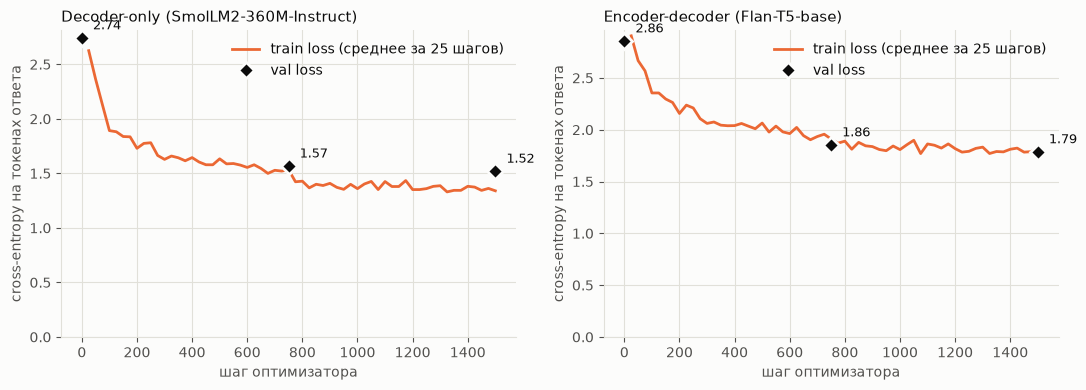

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, kind in zip(axes, ["decoder", "encdec"]):
    log = get_training(kind)
    steps, losses = zip(*log["loss_log"])
    ax.plot(steps, losses, color=C_TUNED, linewidth=2, label="train loss (среднее за 25 шагов)")
    vs, vl = zip(*log["val_loss"])
    ax.plot(vs, vl, "D", color=INK, markersize=8, markeredgecolor=SURFACE, markeredgewidth=2, label="val loss")
    for s, v in log["val_loss"]:
        ax.annotate(f"{v:.2f}", (s, v), textcoords="offset points", xytext=(8, 6), color=INK, fontsize=9)
    ax.set_title(MODELS[kind]["title"], loc="left", fontsize=11)
    ax.set_xlabel("шаг оптимизатора")
    ax.set_ylabel("cross-entropy на токенах ответа")
    ax.set_ylim(bottom=0)
    ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "fig_training.png"), dpi=150)
plt.show()

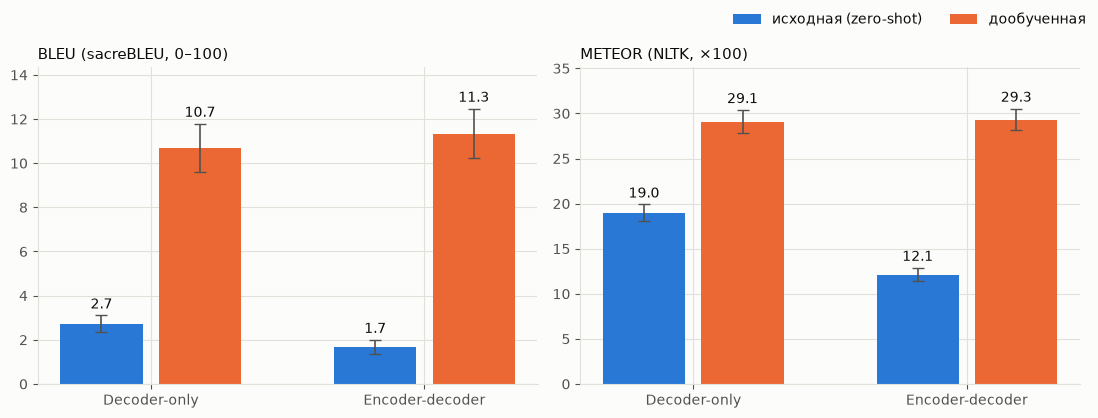

In [23]:
reports = {k: bootstrap_report(k) for k in MODELS}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (title, key, scale) in zip(axes, [("BLEU (sacreBLEU, 0–100)", "bleu", 1), ("METEOR (NLTK, ×100)", "meteor", 100)]):
    top = max(reports[kind][f"{key}_{stage}"][1] for kind in MODELS for stage in ("base", "tuned"))
    for gi, kind in enumerate(MODELS):
        for bi, (stage, color, label) in enumerate([("base", C_BASE, "исходная (zero-shot)"), ("tuned", C_TUNED, "дообученная")]):
            r = get_eval(kind, stage)
            val = r["bleu"] if key == "bleu" else 100 * r["meteor_mean"]
            lo, hi = reports[kind][f"{key}_{stage}"]
            x = gi + (bi - 0.5) * 0.36
            ax.bar(x, val, width=0.30, color=color, label=label if gi == 0 else None)
            ax.errorbar(x, val, yerr=[[val - lo], [hi - val]], color=INK2, capsize=4, linewidth=1.2)
            ax.annotate(f"{val:.1f}", (x, hi), textcoords="offset points", xytext=(0, 5), ha="center", color=INK, fontsize=10)
    ax.set_xticks(range(len(MODELS)), [MODELS[k]["short"] for k in MODELS])
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylim(0, 1.15 * top)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig(os.path.join(RESULTS_DIR, "fig_metrics.png"), dpi=150)
plt.show()

## Сводная таблица

In [24]:
rows = []
for kind in MODELS:
    for stage in ["base", "tuned"]:
        r = get_eval(kind, stage)
        rows.append({"модель": MODELS[kind]["title"], "стадия": STAGE_TITLE[stage], "BLEU": round(r["bleu"], 2),
                     "METEOR ×100": round(100 * r["meteor_mean"], 2), "средняя длина ответа, слов": round(r["hyp_words"], 1)})
summary = pd.DataFrame(rows).set_index(["модель", "стадия"])
display(summary)
summary.to_csv(os.path.join(RESULTS_DIR, "summary.csv"), encoding="utf-8-sig")

BLEU  METEOR ×100  средняя длина ответа, слов
модель                               стадия                                                                     
Decoder-only (SmolLM2-360M-Instruct) исходная модель (zero-shot)   2.70        18.96                        21.3
                                     дообученная модель           10.70        29.06                        14.9
Encoder-decoder (Flan-T5-base)       исходная модель (zero-shot)   1.65        12.12                         7.2
                                     дообученная модель           11.32        29.33                        14.8

## Модели между собой (ориентировочно)

Парный bootstrap по тем же 1000 валидационным примерам: разность «encoder-decoder − decoder-only» на одной и той
же стадии. Напоминание: модели различаются размером (248M и 362M), данными предобучения и токенизатором, поэтому это
сравнение показывает, кто лучше в данной постановке, а не «какая архитектура лучше вообще».

Дополнительно - штраф за краткость (brevity penalty, BP) из BLEU: при BP < 1 BLEU домножается на этот коэффициент,
если ответы в среднем короче эталонов.

In [25]:
def cross_model_table(B=N_BOOTSTRAP, seed=0):
    rows = []
    for stage in ["base", "tuned"]:
        a, b = get_eval("decoder", stage), get_eval("encdec", stage)
        sa, sb = bleu_stats(a["hyps"], REFS), bleu_stats(b["hyps"], REFS)
        ma, mb = np.array(a["meteor"]), np.array(b["meteor"])
        rg, n = np.random.default_rng(seed), len(REFS)
        d_bleu, d_met = [], []
        for _ in range(B):
            idx = rg.integers(0, n, n)
            d_bleu.append(bleu_from_stats(sb[idx]) - bleu_from_stats(sa[idx]))
            d_met.append(100 * (mb[idx].mean() - ma[idx].mean()))
        for name, d, point in [("BLEU", d_bleu, b["bleu"] - a["bleu"]),
                               ("METEOR (×100)", d_met, 100 * (b["meteor_mean"] - a["meteor_mean"]))]:
            lo, hi = np.percentile(d, [2.5, 97.5])
            rows.append({"стадия": STAGE_TITLE[stage], "метрика": name,
                         "Δ (enc-dec − decoder) [95% CI]": f"{point:+.2f} [{lo:+.2f}; {hi:+.2f}]",
                         "Δ значима": "да" if lo > 0 or hi < 0 else "нет"})
    return pd.DataFrame(rows).set_index(["стадия", "метрика"])


display(cross_model_table())

bp_rows = []
for kind in MODELS:
    for stage in ["base", "tuned"]:
        s = sacrebleu.corpus_bleu(get_eval(kind, stage)["hyps"], [REFS], force=True)
        bp_rows.append({"модель": MODELS[kind]["short"], "стадия": STAGE_TITLE[stage], "BLEU": round(s.score, 2),
                        "brevity penalty": round(s.bp, 3), "длина ответов / длина эталонов": round(s.sys_len / s.ref_len, 2)})
display(pd.DataFrame(bp_rows).set_index(["модель", "стадия"]))

Δ (enc-dec − decoder) [95% CI] Δ значима
стадия                      метрика                                               
исходная модель (zero-shot) BLEU                    -1.05 [-1.48; -0.62]        да
                            METEOR (×100)           -6.84 [-7.76; -5.85]        да
дообученная модель          BLEU                    +0.62 [-0.37; +1.58]       нет
                            METEOR (×100)           +0.27 [-0.82; +1.37]       нет

BLEU  brevity penalty  длина ответов / длина эталонов
модель          стадия                                                                             
Decoder-only    исходная модель (zero-shot)   2.70            1.000                            1.42
                дообученная модель           10.70            0.973                            0.97
Encoder-decoder исходная модель (zero-shot)   1.65            0.355                            0.49
                дообученная модель           11.32            0.987                            0.99

## Выводы

**Данные:** MultiWOZ 2.2, обучающий сабсет 12 000 примеров, метрики на валидационном сабсете из 1 000 примеров.
Две модели дообучены полностью (2 эпохи, эффективный батч 16). 95 %-интервалы - bootstrap по валидационным примерам.

| Модель | Стадия | BLEU | METEOR ×100 | Длина ответа, слов (эталон 15.0) | Brevity penalty |
|---|---|---|---|---|---|
| Decoder-only (SmolLM2-360M) | исходная | 2.70 [2.35; 3.11] | 18.96 [18.03; 19.91] | 21.3 | 1.000 |
| | дообученная | **10.70** [9.61; 11.79] | **29.06** [27.80; 30.38] | 14.9 | 0.973 |
| | Δ | **+8.00** [+6.88; +9.16] | **+10.10** [+8.74; +11.41] | | |
| Encoder-decoder (Flan-T5-base) | исходная | 1.65 [1.35; 2.00] | 12.12 [11.40; 12.89] | 7.2 | 0.355 |
| | дообученная | **11.32** [10.25; 12.47] | **29.33** [28.11; 30.53] | 14.8 | 0.987 |
| | Δ | **+9.67** [+8.54; +10.77] | **+17.20** [+15.97; +18.52] | | |

**1. Дообучение резко улучшило обе модели, и это не шум.** BLEU вырос в 4 раза у decoder-only (2.70 → 10.70) и в 7 раз у
encoder-decoder (1.65 → 11.32), METEOR - на 10 и 17 пунктов. Все доверительные интервалы разностей далеки от нуля.
Val-loss при этом падал обе эпохи (2.74 → 1.57 → 1.52 и 2.86 → 1.86 → 1.79) с замедлением во второй эпохе; признаков
переобучения за две эпохи нет (больше эпох или данных я не пробовал).

**2. Значительная часть выигрыша - калибровка стиля и длины ответа, а не новые знания.** Исходный decoder-only
слишком многословен (21.3 слова при эталоне 15.0; в примерах встречаются отказы вроде «as an AI, I don't have
real-time access…»), исходный Flan-T5 - наоборот, слишком краток (7.2 слова, длина ответов 0.49 от эталонной), из-за
чего BLEU умножается на brevity penalty 0.355. После дообучения обе модели выдают ответы эталонной длины (14.9 и 14.8) в
стиле датасета: уточняющие вопросы, предложение забронировать, «Is there anything else…».

**3. Рост метрик не означает фактической правильности.** У моделей нет доступа к базе данных, поэтому дообученные модели
уверенно придумывают детали: номера броней (`YZZZZZX`, `10099988`), время поезда («leaving at 11:01 and arriving at 11:07»).
BLEU/METEOR поощряют сходство по словам, а не истинность. Для реальной системы в вход нужно подавать результаты поиска
по базе или состояние диалога - в этой работе этого нет. Это же объясняет невысокие абсолютные значения
(BLEU ≈ 11, METEOR ≈ 29).

**4. Сравнение моделей между собой (ориентировочное, см. оговорку в разделе 1).**
* **До дообучения** decoder-only значимо лучше (Δ BLEU −1.05, METEOR −6.84 в пользу decoder-only), но этот разрыв почти
  целиком объясняется длиной: у Flan-T5 штраф за краткость 0.355 - без него его BLEU был бы ≈ 4.6, то есть выше, чем у
  decoder-only (2.70); а METEOR сильнее взвешивает полноту (recall), поэтому тоже наказывает слишком короткие ответы.
* **После дообучения** различие не обнаружено: BLEU +0.62 [−0.37; +1.58], METEOR +0.27 [−0.82; +1.37] в пользу
  encoder-decoder, интервалы содержат 0. При меньшем размере Flan-T5 дообучился вдвое быстрее (9.8 против 19.2 мин) и
  занял меньше памяти (4.3 против 6.6 ГиБ), но тут размер модели и размер микро-батча не контролировались.

**Ограничения:**
* по одному запуску дообучения на модель (seed 0): интервалы учитывают разброс валидационной выборки, но не разброс от
  случайности обучения и гиперпараметров (скорости обучения не подбирались);
* zero-shot зависит от формулировки промпта: я один раз переписал инструкцию после того, как первый вариант (со словами
  «system side of a dialogue») вызвал отказы у decoder-only на смоук-тесте; дальше подбор промпта не проводился;
* жадное декодирование, подмножества данных (12 000 из 56 776 обучающих примеров), одна случайная выборка
  1 000 валидационных примеров;
* BLEU и METEOR слабо отражают качество диалога (ответ может быть уместным и при низком пересечении с эталоном).

Дообученные веса сохранены в `checkpoints_lab2/decoder` и `checkpoints_lab2/encdec`.